### Step 1: Import Libraries and Load Datasets

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Load datasets
try:
    app_df = pd.read_csv('application_record.csv')
    credit_df = pd.read_csv('credit_record.csv')
    print("Datasets loaded successfully!")
    print(f"Application record shape: {app_df.shape}")
    print(f"Credit record shape: {credit_df.shape}")
except FileNotFoundError as e:
    print(f"Error: {e}. Please ensure application_record.csv and credit_record.csv are uploaded to your environment.")

Datasets loaded successfully!
Application record shape: (438557, 18)
Credit record shape: (1048575, 3)


### Step 2: Define Target Label from Credit Record
In `credit_record.csv`, the `STATUS` column represents the payment behavior (e.g., C: paid off, X: no debt, 0: 1-29 days overdue, up to 5: late over 150 days). We will classify clients with debts overdue by 30 days or more (STATUS 1 to 5) as "Risk/Bad" (1), and others as "Approved/Good" (0).

In [ ]:
# Map status to binary labels
# 1, 2, 3, 4, 5 represent past-due loans -> Bad (1)
# C, X, 0 represent on-time or slightly late -> Good (0)
credit_df['TARGET'] = credit_df['STATUS'].map({
    'C': 0, 'X': 0, '0': 0,
    '1': 1, '2': 1, '3': 1, '4': 1, '5': 1
})

# Group by ID and find if a user ever had a 'Bad' status
user_target = credit_df.groupby('ID')['TARGET'].max().reset_index()
print("Target distribution from credit records:")
print(user_target['TARGET'].value_counts(normalize=True))

Target distribution from credit records:
TARGET
0    0.883658
1    0.116342
Name: proportion, dtype: float64


### Step 3: Merge and Clean the Datasets

In [ ]:
# Merge datasets on 'ID'
df = pd.merge(app_df, user_target, on='ID', how='inner')
print(f"Merged dataset shape: {df.shape}")

# Drop duplicates based on features (excluding ID)
features_cols = [col for col in df.columns if col != 'ID']
df = df.drop_duplicates(subset=features_cols)
print(f"Shape after dropping duplicates: {df.shape}")

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Fill missing values in OCCUPATION_TYPE with 'Unknown'
df['OCCUPATION_TYPE'] = df['OCCUPATION_TYPE'].fillna('Unknown')

Merged dataset shape: (36457, 19)
Shape after dropping duplicates: (11394, 19)

Missing values:
OCCUPATION_TYPE    3488
dtype: int64


### Step 4: Feature Preprocessing and Encoding

In [ ]:
# Convert DAYS_BIRTH to AGE and DAYS_EMPLOYED to YEARS_EMPLOYED
df['AGE'] = -df['DAYS_BIRTH'] // 365
df['YEARS_EMPLOYED'] = -df['DAYS_EMPLOYED'] / 365
# Handle pensioners or unemployed (where DAYS_EMPLOYED is positive)
df['YEARS_EMPLOYED'] = df['YEARS_EMPLOYED'].apply(lambda x: 0 if x < 0 else x)

# Drop original columns we transformed or don't need
df = df.drop(columns=['ID', 'DAYS_BIRTH', 'DAYS_EMPLOYED'])

# Encode categorical variables
cat_cols = df.select_dtypes(include=['object']).columns
le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col].astype(str))

display(df.head())

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,TARGET,AGE,YEARS_EMPLOYED
0,1,1,1,0,427500.0,4,1,0,4,1,1,0,0,17,2.0,1,32,12.443836
2,1,1,1,0,112500.0,4,4,1,1,1,0,0,0,16,2.0,0,58,3.106849
3,0,0,1,0,270000.0,0,4,3,1,1,0,1,1,14,1.0,0,52,8.358904
7,0,0,1,0,283500.0,1,1,2,1,1,0,0,0,17,1.0,0,61,0.000000
10,1,1,1,0,270000.0,4,1,1,1,1,1,1,1,0,2.0,0,46,2.106849


### Step 5: Split Data, Handle Imbalance and Train Model

In [ ]:
X = df.drop(columns=['TARGET'])
y = df['TARGET']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale numerical variables
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train a Random Forest model with class weights to manage class imbalance
model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
model.fit(X_train_scaled, y_train)

# Predict
y_pred = model.predict(X_test_scaled)

print("Training completed.")

Training completed.


### Step 6: Evaluate Model Performance

Accuracy: 0.6700

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.84      0.80      1798
           1       0.04      0.03      0.03       481

    accuracy                           0.67      2279
   macro avg       0.40      0.43      0.42      2279
weighted avg       0.61      0.67      0.64      2279



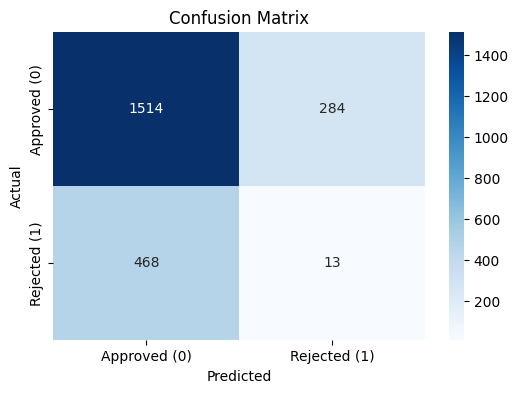

In [ ]:
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Approved (0)', 'Rejected (1)'], yticklabels=['Approved (0)', 'Rejected (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

### Step 7: Apply SMOTE to Balance the Training Set and Retrain

In [ ]:
from imblearn.over_sampling import SMOTE

# Instantiate SMOTE
smote = SMOTE(random_state=42)

# Resample the scaled training data
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

print(f"Original training shape: {X_train_scaled.shape}")
print(f"Balanced training shape: {X_train_balanced.shape}")
print("\nBalanced class distribution:")
print(pd.Series(y_train_balanced).value_counts())

Original training shape: (9115, 17)
Balanced training shape: (14384, 17)

Balanced class distribution:
TARGET
0    7192
1    7192
Name: count, dtype: int64


Accuracy after SMOTE: 0.6468

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.81      0.78      1798
           1       0.06      0.05      0.05       481

    accuracy                           0.65      2279
   macro avg       0.41      0.43      0.42      2279
weighted avg       0.61      0.65      0.63      2279



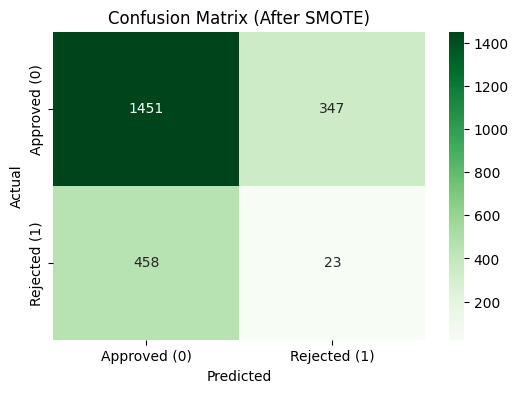

In [ ]:
# Retrain Random Forest on SMOTE balanced training data
balanced_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
balanced_model.fit(X_train_balanced, y_train_balanced)

# Predict on the same scaled test set
y_pred_balanced = balanced_model.predict(X_test_scaled)

# Print metrics
print(f"Accuracy after SMOTE: {accuracy_score(y_test, y_pred_balanced):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_balanced))

# Plot new Confusion Matrix
cm_balanced = confusion_matrix(y_test, y_pred_balanced)
plt.figure(figsize=(6,4))
sns.heatmap(cm_balanced, annot=True, fmt='d', cmap='Greens', xticklabels=['Approved (0)', 'Rejected (1)'], yticklabels=['Approved (0)', 'Rejected (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (After SMOTE)')
plt.show()

### Step 8: Analyze and Plot Feature Importances

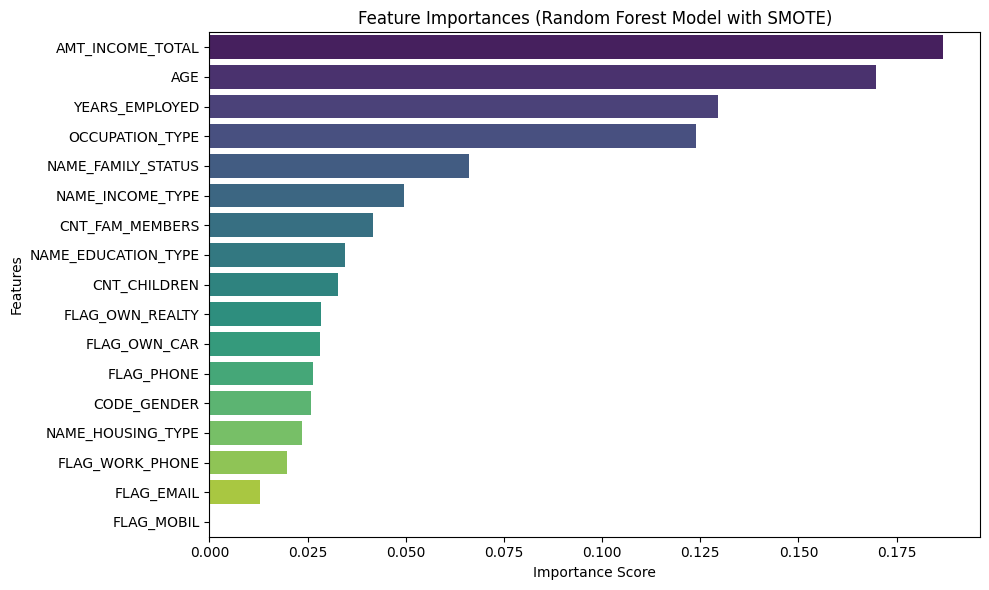

In [ ]:
# Retrieve feature importances from the balanced model
importances = balanced_model.feature_importances_
feature_names = X.columns

# Create a DataFrame for visualization
feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis', hue='Feature', legend=False)
plt.title('Feature Importances (Random Forest Model with SMOTE)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### Step 9: Save the Model and Scaler for Production

In [ ]:
import joblib

# Save the trained model and standard scaler
joblib.dump(balanced_model, 'credit_card_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Model and Scaler have been successfully saved to disk!")

Model and Scaler have been successfully saved to disk!


### Step 10: Helper Function for Real-Time Predictions
Let's write a utility function that accepts raw application features, scales them correctly, and uses our saved model to decide if a card is approved or rejected.

In [ ]:
def predict_approval(new_data_df):
    """
    Loads model artifacts and returns card approval predictions.
    Inputs: a DataFrame containing raw feature columns (matching X.columns)
    Outputs: Predictions (0 = Approved, 1 = Rejected)
    """
    # Load saved model and scaler
    loaded_model = joblib.load('credit_card_model.pkl')
    loaded_scaler = joblib.load('scaler.pkl')

    # Scale features
    scaled_features = loaded_scaler.transform(new_data_df)

    # Make prediction
    prediction = loaded_model.predict(scaled_features)
    return ["Rejected (High Risk)" if p == 1 else "Approved (Low Risk)" for p in prediction]

# Test the function using a sample row from our test set
sample_application = X_test.iloc[[0]]
prediction_result = predict_approval(sample_application)

print("Sample Application Features:")
display(sample_application)
print(f"\nModel Decision: {prediction_result[0]}")

Sample Application Features:


,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,AGE,YEARS_EMPLOYED
8640,0,0,1,0,157500.0,4,4,1,1,1,0,0,0,3,2.0,41,7.290411



Model Decision: Approved (Low Risk)
